<a href="https://colab.research.google.com/github/Sarveshchougule/OpenGL_WebGL_Assignments/blob/Skc_branch/TUD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total riders in dataset before removing zero value : 184
Total riders in dataset after removing zero value : 176
               95th
rider_class        
All Rounder  228.75
Climber      153.70
Sprinter     183.40
Unclassed    104.80
               95th
stage_class        
Flat         140.80
Hills        154.00
Mountain     179.65
                           95th
rider_class stage_class        
All Rounder Flat          93.05
            Hills        199.60
            Mountain     268.25
Climber     Flat          18.35
            Hills        160.75
            Mountain     174.40
Sprinter    Flat         226.00
            Hills         67.80
            Mountain      32.00
Unclassed   Flat          69.00
            Hills        140.20
            Mountain      39.90

Mean Scores:
   stage_class     points
0        Flat  28.492341
1       Hills  32.333333
2    Mountain  38.467532

Mean Scores:
    rider_class     points
0  All Rounder  58.524038
1      Climber  33.011236
2     Sprin

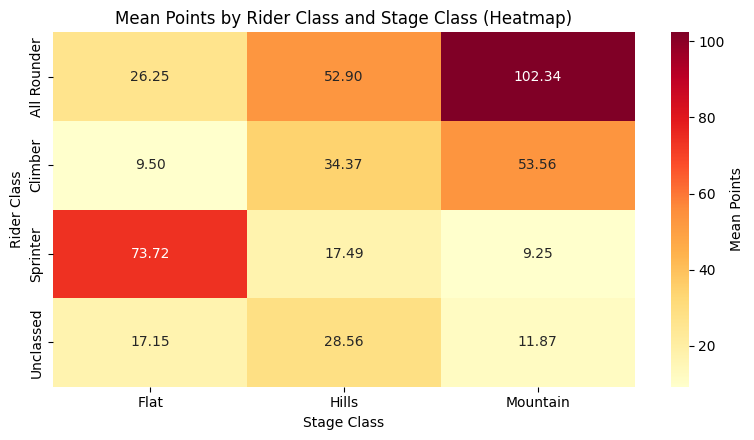

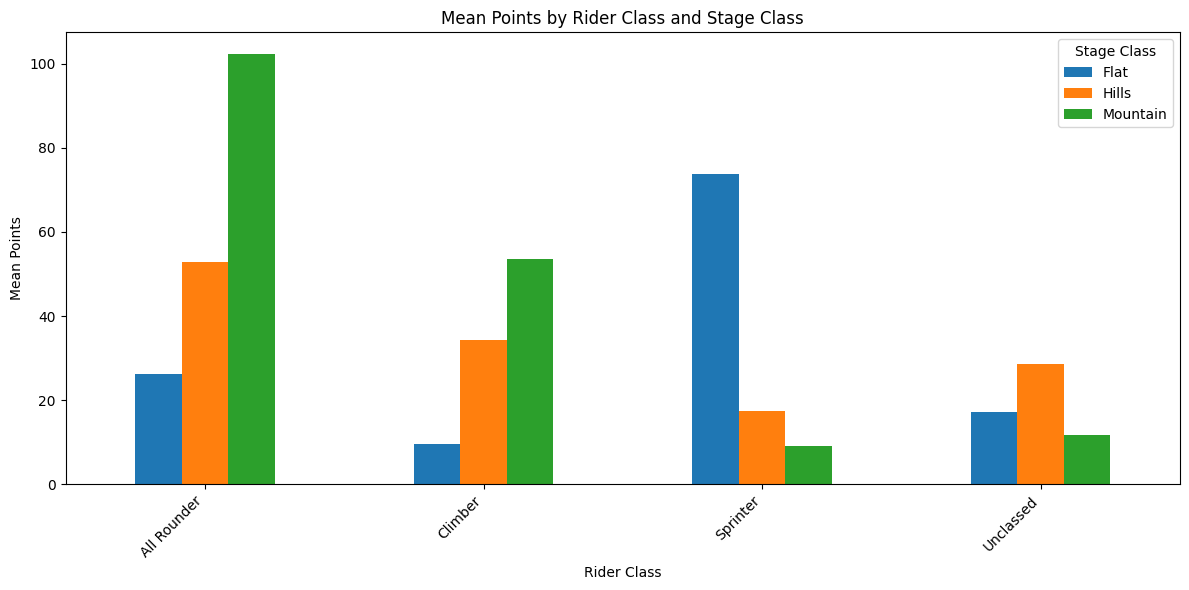

<Figure size 800x600 with 0 Axes>

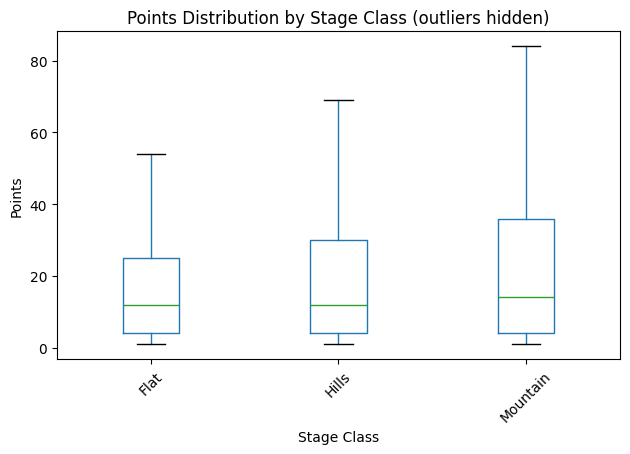

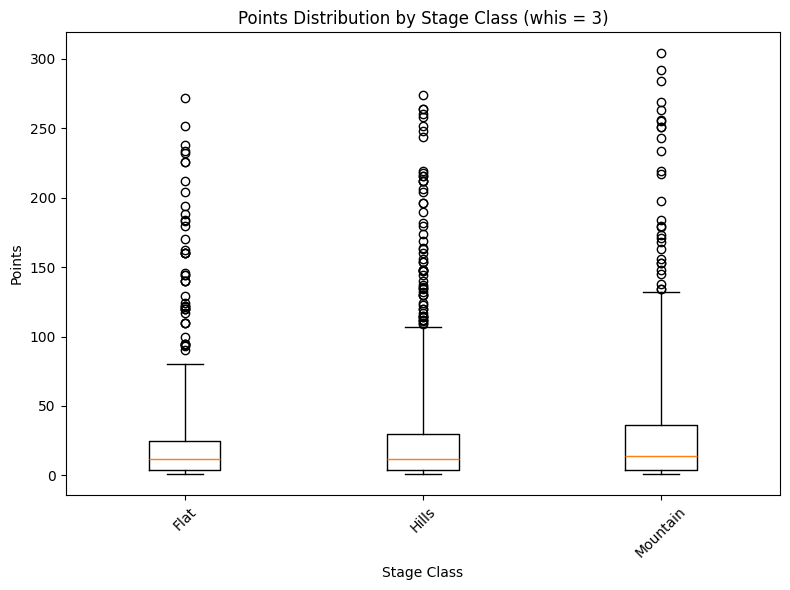

In [ ]:
import pandas as skc_pd
import matplotlib.pyplot as skc_plt
import seaborn as skc_sns

skc_link = "https://statistik.tu-dortmund.de/storages/statistik/r/Downloads/Studium/Studiengaenge-Infos/Data_Science/cycling.txt"
skc_data = skc_pd.read_csv(skc_link, sep = " ")
skc_data["stage_class"] = skc_data["stage_class"].map({ "flat": "Flat", "hills": "Hills", "mount": "Mountain" })

print(f"Total riders in dataset before removing zero value : { len( skc_data["all_riders"].unique() ) }")
skc_data = skc_data[ skc_data["points"] > 0 ]
print(f"Total riders in dataset after removing zero value : { len( skc_data["all_riders"].unique() ) }")

skc_percentiles = [0.95]

skc_rider_percentiles = ( skc_data.groupby('rider_class')['points'].quantile(skc_percentiles).unstack() )
skc_rider_percentiles.columns = ['95th']
print(skc_rider_percentiles)

skc_stage_percentiles = ( skc_data.groupby('stage_class')['points'].quantile(skc_percentiles).unstack() )
skc_stage_percentiles.columns = ['95th']
print(skc_stage_percentiles)

skc_grouped_percentiles = ( skc_data.groupby(['rider_class', 'stage_class'])['points'].quantile(skc_percentiles).unstack() )
skc_grouped_percentiles.columns = ['95th']
print(skc_grouped_percentiles)


skc_scores_SC = skc_data.groupby(["stage_class"])["points"].mean().reset_index()
print("\nMean Scores:\n", skc_scores_SC)

skc_scores_RC = skc_data.groupby(["rider_class"])["points"].mean().reset_index()
print("\nMean Scores:\n", skc_scores_RC)

skc_grouped_scores_mean = skc_data.groupby(["rider_class", "stage_class"])["points"].mean().reset_index()
print("\nGrouped Mean Scores:\n", skc_grouped_scores_mean)


skc_mean_points = skc_data.groupby( ['rider_class', 'stage_class'] )['points'].mean().unstack().fillna(0)
skc_cols = ['Flat', 'Hills', 'Mountain']

skc_heat_df = skc_mean_points.reindex( columns = skc_cols ).fillna(0)
skc_plt.figure( figsize = ( 8, 4.5 ) )
skc_sns.heatmap( skc_heat_df, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={ 'label': 'Mean Points' } )
skc_plt.title( 'Mean Points by Rider Class and Stage Class (Heatmap)' )
skc_plt.xlabel( 'Stage Class' )
skc_plt.ylabel( 'Rider Class' )
skc_plt.tight_layout()
skc_plt.show()

skc_mean_points = skc_data.groupby( ['rider_class', 'stage_class'] )['points'].mean().unstack().fillna(0)
#print(skc_mean_points)

skc_ax = skc_mean_points.plot( kind='bar', figsize=(12, 6) )
skc_ax.set_title( 'Mean Points by Rider Class and Stage Class' )
skc_ax.set_xlabel( 'Rider Class' )
skc_ax.set_ylabel( 'Mean Points' )
skc_ax.legend( title='Stage Class' )
skc_plt.xticks( rotation=45, ha='right' )
skc_plt.tight_layout()
skc_plt.show()

skc_plt.figure( figsize = ( 8, 6 ) )
skc_data.boxplot( column = 'points', by = 'stage_class', grid = False, showfliers = False )
skc_plt.title( 'Points Distribution by Stage Class (outliers hidden)' )
skc_plt.suptitle('')  # remove pandas default suptitle
skc_plt.xlabel( 'Stage Class' )
skc_plt.ylabel( 'Points' )
skc_plt.xticks( rotation=45 )
skc_plt.tight_layout()
skc_plt.show()

skc_groups = [ skc_data[ skc_data['rider_class'] == skc_rc]['points'] for skc_rc in skc_data['rider_class'].unique()]
skc_grouped = skc_data.groupby('stage_class')['points']
skc_labels = list( skc_grouped.groups.keys() )
skc_data_to_plot = [ skc_grouped.get_group(skc_g).values for skc_g in skc_labels ]
skc_plt.figure( figsize=(8,6) )
skc_plt.boxplot( skc_data_to_plot, tick_labels = skc_labels, whis = 3, showfliers = True )
skc_plt.title( 'Points Distribution by Stage Class (whis = 3)' )
skc_plt.xlabel( 'Stage Class' )
skc_plt.ylabel( 'Points' )
skc_plt.xticks( rotation = 45 )
skc_plt.tight_layout()
skc_plt.show()


Summation Scores:
   stage_class  points
0        Flat   13021
1       Hills   18430
2    Mountain   11848

Mean Scores:
   stage_class     points
0        Flat  11.794384
1       Hills  12.520380
2    Mountain  12.878261

Median Scores:
   stage_class  points
0        Flat     0.0
1       Hills     0.0
2    Mountain     0.0

Standard Deviation Scores:
   stage_class     points
0        Flat  33.219268
1       Hills  36.130357
2    Mountain  39.906588

Variance Scores:
   stage_class       points
0        Flat  1103.519787
1       Hills  1305.402711
2    Mountain  1592.535762

Summation Scores:
    rider_class  points
0  All Rounder   12173
1      Climber    8814
2     Sprinter    8285
3    Unclassed   14027

Mean Scores:
    rider_class     points
0  All Rounder  37.687307
1      Climber  20.169336
2     Sprinter  15.036298
3    Unclassed   6.419680

Median Scores:
    rider_class  points
0  All Rounder    12.0
1      Climber     6.0
2     Sprinter     0.0
3    Unclassed     0.0

Sta

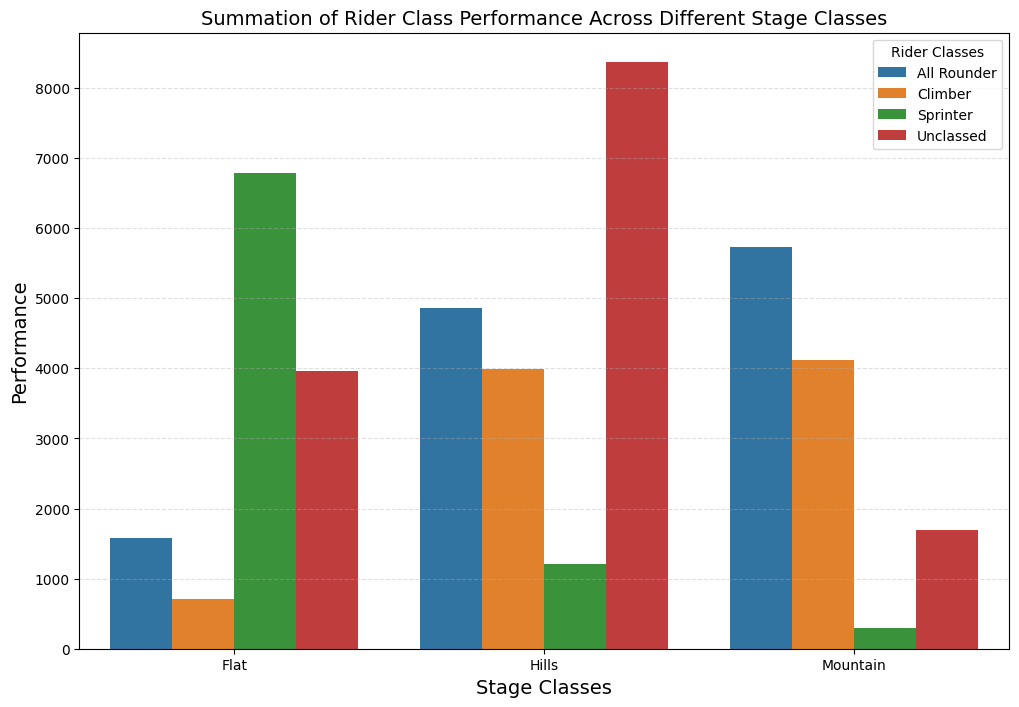


Grouped Mean Scores:
     rider_class stage_class     points
0   All Rounder        Flat  15.441176
1   All Rounder       Hills  35.786765
2   All Rounder    Mountain  67.423529
3       Climber        Flat   5.094203
4       Climber       Hills  21.668478
5       Climber    Mountain  35.860870
6      Sprinter        Flat  38.977011
7      Sprinter       Hills   5.202586
8      Sprinter    Mountain   2.041379
9     Unclassed        Flat   5.740580
10    Unclassed       Hills   9.096739
11    Unclassed    Mountain   2.951304


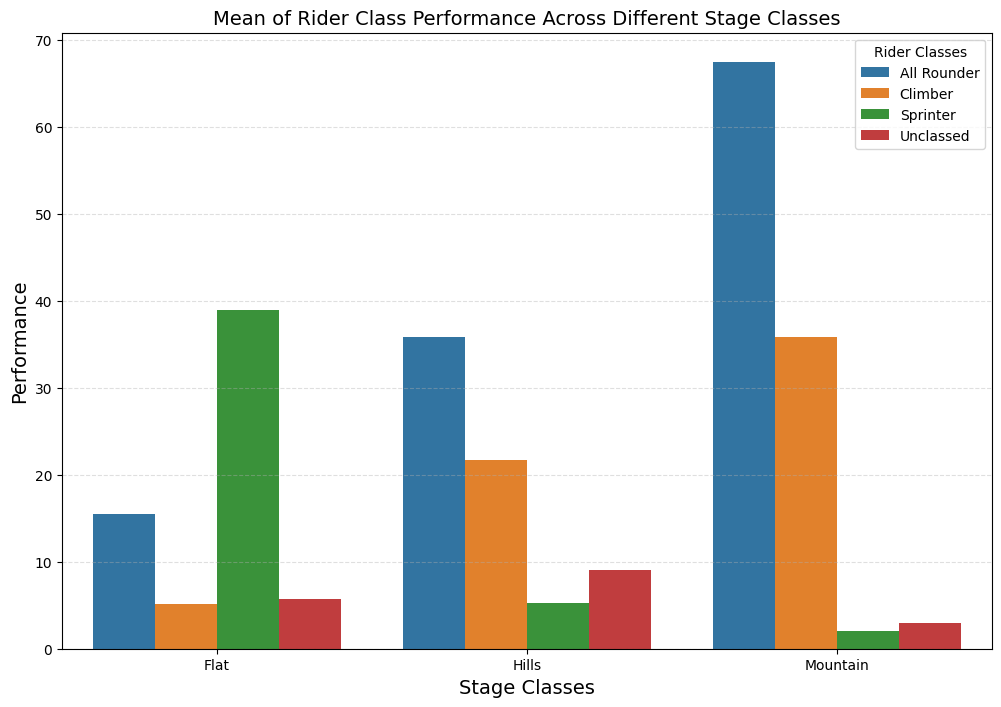


Grouped Median Scores:
     rider_class stage_class  points
0   All Rounder        Flat     8.0
1   All Rounder       Hills    12.5
2   All Rounder    Mountain    17.0
3       Climber        Flat     1.5
4       Climber       Hills     7.0
5       Climber    Mountain    12.0
6      Sprinter        Flat     2.5
7      Sprinter       Hills     0.0
8      Sprinter    Mountain     0.0
9     Unclassed        Flat     0.0
10    Unclassed       Hills     0.0
11    Unclassed    Mountain     0.0


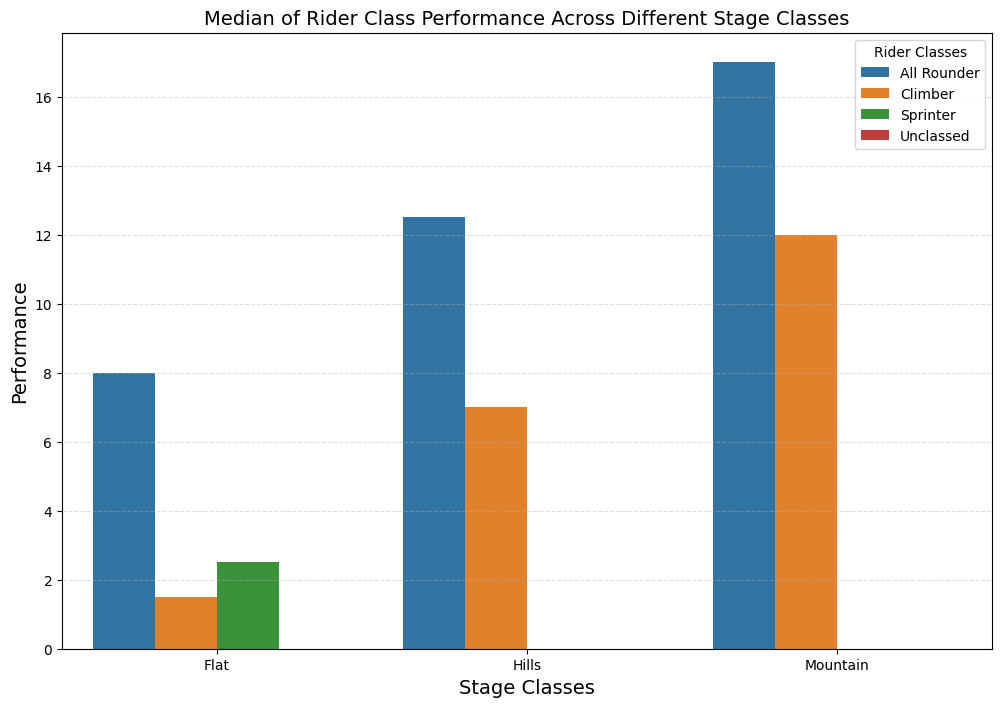


Grouped Standard Deviation Scores:
     rider_class stage_class     points
0   All Rounder        Flat  28.281671
1   All Rounder       Hills  57.459217
2   All Rounder    Mountain  88.955898
3       Climber        Flat   6.230239
4       Climber       Hills  45.984482
5       Climber    Mountain  57.019985
6      Sprinter        Flat  63.588267
7      Sprinter       Hills  21.950897
8      Sprinter    Mountain   5.886515
9     Unclassed        Flat  19.801356
10    Unclassed       Hills  30.662585
11    Unclassed    Mountain   7.905654


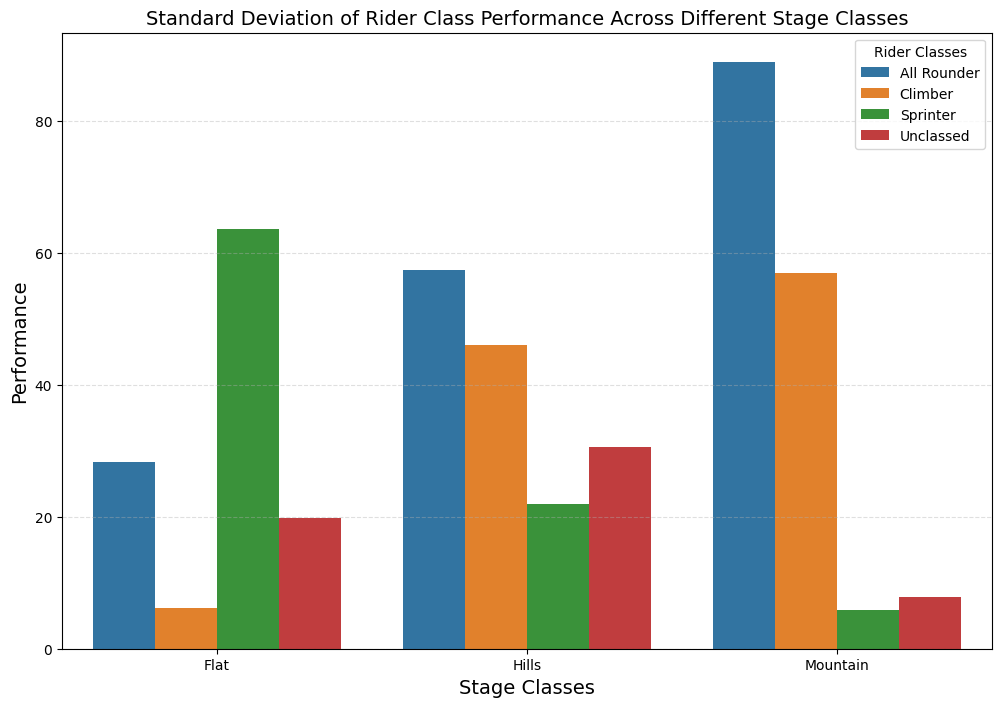


Grouped Variance Scores:
     rider_class stage_class       points
0   All Rounder        Flat   799.852941
1   All Rounder       Hills  3301.561601
2   All Rounder    Mountain  7913.151821
3       Climber        Flat    38.815879
4       Climber       Hills  2114.572553
5       Climber    Mountain  3251.278719
6      Sprinter        Flat  4043.467677
7      Sprinter       Hills   481.841898
8      Sprinter    Mountain    34.651054
9     Unclassed        Flat   392.093706
10    Unclassed       Hills   940.194113
11    Unclassed    Mountain    62.499367


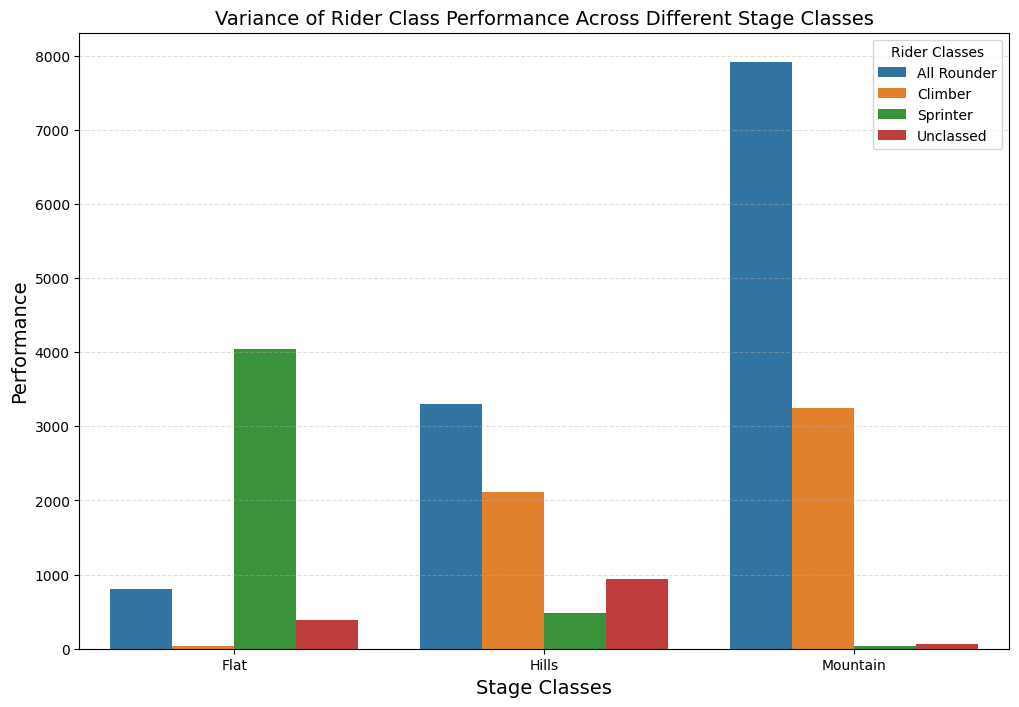

In [ ]:
import pandas as skc_pd
import matplotlib.pyplot as skc_plt
import seaborn as skc_sns

# Loading dataset directly from the URL
skc_url = "https://statistik.tu-dortmund.de/storages/statistik/r/Downloads/Studium/Studiengaenge-Infos/Data_Science/cycling.txt"

# Read the dataset and trim the extra space
skc_dataframe = skc_pd.read_csv(skc_url, sep=' ')[["all_riders", "rider_class", "stage", "points", "stage_class"]]

# Renaming the stage_class to more suitable names
skc_dataframe["stage_class"] = skc_dataframe["stage_class"].map({ "flat": "Flat", "hills": "Hills", "mount": "Mountain" })

# Get individual rider class and stage class summation, mean, median, standard deviation, variance of the performance points
skc_scores_SC = skc_dataframe.groupby(["stage_class"])["points"].sum().reset_index()
print("\nSummation Scores:\n", skc_scores_SC)

skc_scores_SC = skc_dataframe.groupby(["stage_class"])["points"].mean().reset_index()
print("\nMean Scores:\n", skc_scores_SC)

skc_scores_SC = skc_dataframe.groupby(["stage_class"])["points"].median().reset_index()
print("\nMedian Scores:\n", skc_scores_SC)

skc_scores_SC = skc_dataframe.groupby(["stage_class"])["points"].std().reset_index()
print("\nStandard Deviation Scores:\n", skc_scores_SC)

skc_scores_SC = skc_dataframe.groupby(["stage_class"])["points"].var().reset_index()
print("\nVariance Scores:\n", skc_scores_SC)

skc_scores_RC = skc_dataframe.groupby(["rider_class"])["points"].sum().reset_index()
print("\nSummation Scores:\n", skc_scores_RC)

skc_scores_RC = skc_dataframe.groupby(["rider_class"])["points"].mean().reset_index()
print("\nMean Scores:\n", skc_scores_RC)

skc_scores_RC = skc_dataframe.groupby(["rider_class"])["points"].median().reset_index()
print("\nMedian Scores:\n", skc_scores_RC)

skc_scores_RC = skc_dataframe.groupby(["rider_class"])["points"].std().reset_index()
print("\nStandard Deviation Scores:\n", skc_scores_RC)

skc_scores_RC = skc_dataframe.groupby(["rider_class"])["points"].var().reset_index()
print("\nVariance Scores:\n", skc_scores_RC)


# Group by both rider class, stage class and then get sum value of the grouped performance points
skc_grouped_scores_sum = skc_dataframe.groupby(["rider_class", "stage_class"])["points"].sum().reset_index()
print("\nGrouped Sum Scores:\n", skc_grouped_scores_sum)

# Plotting Graph
skc_plt.figure(figsize = (12, 8))
skc_sns.barplot(data = skc_grouped_scores_sum, x = 'stage_class', y = 'points', hue = 'rider_class')

# Styling Graph
skc_plt.title("Summation of Rider Class Performance Across Different Stage Classes", fontsize = 14)
skc_plt.xlabel("Stage Classes", fontsize = 14)
skc_plt.ylabel("Performance", fontsize = 14)
skc_plt.legend(title = "Rider Classes")
skc_plt.grid(axis = 'y', linestyle = '--', alpha = 0.4)

# Display Graph
skc_plt.show()


# Group by both rider class, stage class and then get mean value of the grouped performance points
skc_grouped_scores_mean = skc_dataframe.groupby(["rider_class", "stage_class"])["points"].mean().reset_index()
print("\nGrouped Mean Scores:\n", skc_grouped_scores_mean)

# Plotting Graph
skc_plt.figure(figsize = (12, 8))
skc_sns.barplot(data = skc_grouped_scores_mean, x = 'stage_class', y = 'points', hue = 'rider_class')

# Styling Graph
skc_plt.title("Mean of Rider Class Performance Across Different Stage Classes", fontsize = 14)
skc_plt.xlabel("Stage Classes", fontsize = 14)
skc_plt.ylabel("Performance", fontsize = 14)
skc_plt.legend(title = "Rider Classes")
skc_plt.grid(axis = 'y', linestyle = '--', alpha = 0.4)

# Display Graph
skc_plt.show()


# Group by both rider class, stage class and then get median value of the grouped performance points
skc_grouped_scores_median = skc_dataframe.groupby(["rider_class", "stage_class"])["points"].median().reset_index()
print("\nGrouped Median Scores:\n", skc_grouped_scores_median)

# Plotting Graph
skc_plt.figure(figsize = (12, 8))
skc_sns.barplot(data = skc_grouped_scores_median, x = 'stage_class', y = 'points', hue = 'rider_class')

# Styling Graph
skc_plt.title("Median of Rider Class Performance Across Different Stage Classes", fontsize = 14)
skc_plt.xlabel("Stage Classes", fontsize = 14)
skc_plt.ylabel("Performance", fontsize = 14)
skc_plt.legend(title = "Rider Classes")
skc_plt.grid(axis = 'y', linestyle = '--', alpha = 0.4)

# Display Graph
skc_plt.show()


# Group by both rider class, stage class and then get standard deviation value of the grouped performance points
skc_grouped_scores_std = skc_dataframe.groupby(["rider_class", "stage_class"])["points"].std().reset_index()
print("\nGrouped Standard Deviation Scores:\n", skc_grouped_scores_std)

# Plotting Graph
skc_plt.figure(figsize = (12, 8))
skc_sns.barplot(data = skc_grouped_scores_std, x = 'stage_class', y = 'points', hue = 'rider_class')

# Styling Graph
skc_plt.title("Standard Deviation of Rider Class Performance Across Different Stage Classes", fontsize = 14)
skc_plt.xlabel("Stage Classes", fontsize = 14)
skc_plt.ylabel("Performance", fontsize = 14)
skc_plt.legend(title = "Rider Classes")
skc_plt.grid(axis = 'y', linestyle = '--', alpha = 0.4)

# Display Graph
skc_plt.show()


# Group by both rider class, stage class and then get Variance value of the grouped performance points
skc_grouped_scores_var = skc_dataframe.groupby(["rider_class", "stage_class"])["points"].var().reset_index()
print("\nGrouped Variance Scores:\n", skc_grouped_scores_var)

# Plotting Graph
skc_plt.figure(figsize = (12, 8))
skc_sns.barplot(data = skc_grouped_scores_var, x = 'stage_class', y = 'points', hue = 'rider_class')

# Styling Graph
skc_plt.title("Variance of Rider Class Performance Across Different Stage Classes", fontsize = 14)
skc_plt.xlabel("Stage Classes", fontsize = 14)
skc_plt.ylabel("Performance", fontsize = 14)
skc_plt.legend(title = "Rider Classes")
skc_plt.grid(axis = 'y', linestyle = '--', alpha = 0.4)

# Display Graph
skc_plt.show()

